# EN.605.631 — Properties of Expectation with R (Chapter 7) — Notebook Shell

**Format:** Jupyter Notebook (**R kernel**)  
**Estimated time:** ~5 hours  
**Total points:** 100

This shell provides **function stubs** and **plotting scaffolds**. Replace `TODO` with your code.

## Environment & Setup

In [1]:
# Environment
R.version.string
sessionInfo()
set.seed(631)

# Optional packages (commented). Base R preferred.
# suppressPackageStartupMessages({
#   library(ggplot2)
#   library(dplyr)
# })

[1] "R version 4.6.1 (2026-06-24 ucrt)"

R version 4.6.1 (2026-06-24 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] LC_COLLATE=English_United States.utf8 
[2] LC_CTYPE=English_United States.utf8   
[3] LC_MONETARY=English_United States.utf8
[4] LC_NUMERIC=C                          
[5] LC_TIME=English_United States.utf8    

time zone: America/New_York
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
 [1] digest_0.6.39     IRdisplay_1.1     base64enc_0.1-6   fastmap_1.2.0    
 [5] glue_1.8.1        htmltools_0.5.9   repr_1.1.7        lifecycle_1.0.5  
 [9] cli_3.6.6         vctrs_0.7.3       textshaping_1.0.5 pbdZMQ_0.3-14    
[13] systemfonts_1.3.2 compiler_4.6.1    tools_4.6.1       ragg_1.5.2       
[17] evaluate_1.0.5    pillar_1.11.1     rlang_1.3.0       jsonlite_2.0.0   
[21] crayon_1.5.3      IRkernel_1.

## Helper Utilities (you may add to these)

In [2]:
mc_se_mean <- function(x) sd(x)/sqrt(length(x))
ci95_prop <- function(p_hat, n){
  se <- sqrt(p_hat*(1-p_hat)/n)
  c(lower = max(0, p_hat - 1.96*se),
    upper = min(1, p_hat + 1.96*se))
}

---
## Problem 1 — Linearity of Expectation & Indicators (10 pts)

1. Show analytically that for indicators \(X_i=1\{A_i\}\), \(E[\sum X_i]=\sum P(A_i)\). Use to derive Boole’s inequality.  
2. Simulate \(10^5\) trials of five fair coin flips; estimate \(P(\text{at least one head})\) and compare to the Boole bound.

## 1)

Let $X_i = 1\{A_i\}$ be the indicator of event $A_i$

Since $X_i \in \{0,1\}$, $E[X_i] = 1\cdot P(X_i=1) + 0\cdot P(X_i=0) = P(A_i)$

By linearity of expectation, $E\left[\sum_{i=1}^n X_i\right] = \sum_{i=1}^n E[X_i] = \sum_{i=1}^n P(A_i)$

Let $X$ = the number of events that occur: $\sum_{i=1}^n X_i$ and let $U = 1\{\bigcup_{i=1}^n A_i\}$

If no $A_i$ occurs, then $U = 0 = X$. If at least one $A_i$ occurs, then $U = 1 \le X$, since $X \ge 1$, so $U \le X$

Expectation preserves inequalities, so $P\left(\bigcup_{i=1}^n A_i\right) = E[U] \le E[X] = \sum_{i=1}^n P(A_i)$

Let $A_i = \{1 \text{ if the i-th flip is heads and 0 otherwise}\}$

$P(A_i)=0.5$, so Boole gives $P(\bigcup A_i) \le 5(0.5) = 2.5$

The exact $P(A_i)= 1-(0.5)^5 = 0.96875$

## 2)

In [3]:
# === Analytic derivation (write in Markdown above). ===

# === Simulation scaffold ===
N <- 1e5
flips <- matrix(rbinom(N*5, 1, 0.5), nrow=N)
at_least_one_head <- rowSums(flips) >= 1
p_hat <- mean(at_least_one_head)
ci <- ci95_prop(p_hat, N)

# Boole bound for union of A_i = {i-th flip is Head}: sum P(A_i) = 5*0.5
boole_bound <- 5*0.5

list(p_hat=p_hat, ci=ci, boole_bound=boole_bound, exact=1 - (0.5)^5)

$p_hat
[1] 0.96941

$ci
    lower     upper 
0.9683427 0.9704773 

$boole_bound
[1] 2.5

$exact
[1] 0.96875

The simulated mean matches the exact mean. Boole's bound of $2.5 \ge 0.96875$ holds but is not a very tight bound

---
## Problem 2 — Expectation of Common Distributions (12 pts)

Derive expected values via indicator arguments and validate by simulation:
- Binomial(n,p)
- NegBin(r,p) (use **number of trials until r-th success** parameterization)
- Hypergeometric(N,m,n)

Validate with: Binomial(20,0.3), NegBin(r=4,p=0.25), Hypergeometric(N=100,m=40,n=10).

All three use linearity of expectation which holds with or without independence

#### Binomial$(n,p)$:

Let $X_i=\{1 \text{ if trial } i \text{ is a success and 0 otherwise}\}$

$X=\sum_{i=1}^n X_i$

$P(X_i=1)=p$

$E[X]=\sum_{i=1}^n P(X_i=1)=np$

#### NegBin$(r,p)$:

Let $X=G_1+\cdots+G_r$, where $G_i$ is the number of trials needed for the i-th success after the $(i-1)$-th trial

Each $G_i$ is Geometric$(p)$

$G=\sum_{k\ge 1}1\{G\ge k\}$, and $\{G\ge k\}$ means the first $k-1$ trials all fail, so $P(G\ge k)=(1-p)^{k-1}$

$E[G]=\sum_{k=1}^{\infty}(1-p)^{k-1}=\frac{1}{p}$

$E[X]=\sum_{i=1}^r E[G_i]=\frac{r}{p}$

#### Hypergeometric$(N,m,n)$:

Let $X_i=\{1\text{ if trial } i \text{ is a success and 0 otherwise}\}$

By symmetry, every trial is equally likely to be any of the $N$ items, so $P(X_i=1)=m/N$

$E[X]=\sum_{i=1}^n P(X_i=1)=\frac{nm}{N}$

In [13]:
# === Analytic formulas (state in Markdown). ===
# Bin: E = n p
# NegBin (trials for r-th success): E = r/p
# Hypergeo: E = n * m / N

# === Simulation scaffold ===
set.seed(631)
Nsim <- 2e5

# Binomial
Xb <- rbinom(Nsim, 20, 0.3); mean(Xb)
20 * 0.3
mc_se_mean(Xb)

# Negative Binomial (trials for r-th success) using rnbinom failures + r
failures <- rnbinom(Nsim, size=4, prob=0.25)
Xnb <- failures + 4
mean(Xnb)
4 / 0.25
mc_se_mean(Xnb)

# Hypergeometric
Xh <- rhyper(Nsim, m=40, n=100-40, k=10)
mean(Xh)
(10 * 40) / 100
mc_se_mean(Xh)

[1] 6.00527

[1] 6

[1] 0.004575245

[1] 16.00717

[1] 16

[1] 0.01550354

[1] 4.00084

[1] 4

[1] 0.003300371

---
## Problem 3 — Classical Expectation Problems (12 pts)

1. Hat problem: show \(E[\#\text{matches}] = 1\).  
2. Coupon collector: derive \(E[T_N]=N H_N\) with \(H_N=\sum_{k=1}^N 1/k\).  
3. Validate by simulation for N=10 (≥ 2000 reps).

## 1)

Let $X_i=\{1\text{ if person } i \text{ gets their own hat and 0 otherwise}\}$ and $X=\sum_{i=1}^N X_i$ as the number of matches

Assume hat $i$ is equally likely to land on any of the $N$ people $P(X_i=1)=\frac{1}{N}$

By linearity of expectation $E[X]=\sum_{i=1}^N E[X_i]=\sum_{i=1}^N \frac1N = N\cdot\frac1N = 1$

## 2)

Let $T$ be the number of draws to collect all $N$ coupons and $T=T_1+\cdots+T_N$, where $T_k$ is the number of draws needed to get a new coupon when $k-1$ distinct ones have been drawn

At stage $i$, a probability of a new coupon is $p_k=\frac{N-i+1}{N}$, so $T_i\sim\text{Geometric}(p_i)$ and $E[T_i]=\frac{1}{p_i}=\frac{N}{N-i+1}$

By linearity of expectation $E[T]=\sum_{i=1}^N \frac{N}{N-i+1}=N\sum_{j=1}^N\frac1j = N H_N$

## 3)

In [5]:
# === Simulation scaffolds ===
set.seed(631)

# (1) Hat matching: N people, random permutation; count fixed points
hat_matches <- function(N, reps=5000){
  m <- replicate(reps, sum(sample.int(N) == 1:N))
  c(mean=mean(m), sd=sd(m))
}
hat_matches(10)

# (2) Coupon collector simulation
coupon_time <- function(N){
  seen <- rep(FALSE, N); t <- 0L; count <- 0L
  while(count < N){
    t <- t + 1L
    x <- sample.int(N, 1)
    if(!seen[x]){ seen[x] <- TRUE; count <- count + 1L }
  }
  t
}
reps <- 3000
times <- replicate(reps, coupon_time(10))
mean(times); sd(times)/sqrt(reps)

# Theoretical E = N * sum_{k=1}^N 1/k
N <- 10
N * sum(1 / (1:N))

mean      sd 
1.01000 1.01809

[1] 29.11033

[1] 0.2029439

[1] 29.28968

$H_{10}=\frac{7381}{2520}\approx 2.929 = E[T]\approx 29.29$

---
## Problem 4 — Covariance, Variance of Sums, Correlation (12 pts)

1. Derive \(\operatorname{Var}(\sum X_i)=\sum \operatorname{Var}(X_i)+2\sum_{i<j}\operatorname{Cov}(X_i,X_j)\).  
2. Simulate multinomial counts with n=200, p=(0.2,0.3,0.5); estimate Var/Cov and compare to theory.

## 1)

Let $S=\sum_{i=1}^n X_i$ and $\mu_i=E[X_i]$

By linearity $E[S]=\sum_i \mu_i$

$Var(S)=E\left[\left(\sum_{i=1}^n (X_i-\mu_i)\right)^2\right]=E\left[\sum_{i=1}^n\sum_{j=1}^n (X_i-\mu_i)(X_j-\mu_j)\right]$

$=\sum_{i=1}^n\sum_{j=1}^n Cov(X_i,X_j)$

Split the double sum into the diagonal terms ($i=j$), where $Cov(X_i,X_i)=\mathrm{Var}(X_i)$, and the off-diagonal terms. This covariance matrix is symmetrical so $Cov(X_i,X_j)=Cov(X_j,X_i)$ for each pair where $i<j$

$Var\left(\sum_{i=1}^n X_i\right)=\sum_{i=1}^n Var(X_i)+2\sum_{i<j}Cov(X_i,X_j)$

## 2)


In [6]:
set.seed(631)
reps <- 1e5
p <- c(0.2,0.3,0.5); n <- 200
X <- t(rmultinom(reps, size=n, prob=p))
emp_means <- colMeans(X)
emp_vars  <- apply(X, 2, var)
emp_cov   <- cov(X)

# Theory
th_means <- n*p
th_vars  <- n*p*(1-p)
th_cov   <- matrix(-n*outer(p,p), nrow=3); diag(th_cov) <- th_vars

list(emp_means=emp_means, th_means=th_means, emp_vars=emp_vars, th_vars=th_vars, emp_cov12=emp_cov[1,2], th_cov12=th_cov[1,2])

$emp_means
[1] 40.01088 59.99284 99.99628

$th_means
[1]  40  60 100

$emp_vars
[1] 32.00198 42.04211 50.35135

$th_vars
[1] 32 42 50

$emp_cov12
[1] -11.84637

$th_cov12
[1] -12

The empirical means, variances, and covariances are very close to the exact values and the off-diagonal values of the covariance matrix are negative

---
## Problem 5 — Conditional Expectation & Total Expectation (14 pts)

Miner’s problem: three doors—one exits after 3h, others return after 5h and 7h (back to start).  
1. Derive \(E[X]=15\) by conditioning.  
2. Simulate 1000 miners to estimate mean escape time; compare.

## 1)

Let $X$ be the total time to escape and let $D\in\{1,2,3\}$ be the door chosen with probability $\tfrac13$

There are 3 conditions:

- Door 1: the miner escapes after 3 hours. $E[X\mid D=1]=3$
- Door 2: the miner spends 5 hours and returns to the start. $E[X\mid D=2]=5+E[X]$
- Door 3: the miner spends 7 hours and returns to the start. $E[X\mid D=3]=7+E[X]$.

By the law of total expectation, $E[X]=\sum_{d=1}^3 E[X\mid D=d]\,P(D=d)=E[X]=\tfrac13(3)+\tfrac13\big(5+E[X]\big)+\tfrac13\big(7+E[X]\big)=5+\tfrac23E[X]$

$\tfrac13E[X]=5$

$E[X]=15$

## 2)

In [7]:
# === Simulation scaffold ===
set.seed(631)
miner_time <- function(){
  t <- 0
  repeat{
    door <- sample(1:3, 1)
    if(door == 1){ t <- t + 3; break }
    if(door == 2){ t <- t + 5 } else { t <- t + 7 }
  }
  t
}
times <- replicate(1e4, miner_time())
c(mean_hat = mean(times), se = sd(times)/sqrt(length(times)), theory = 15)

mean_hat         se     theory 
14.8900000  0.1474512 15.0000000

The sample mean falls within 2 SEs of the analytic mean

---
## Problem 6 — Random Walk & Runs (10 pts)

2D random walk with n steps of length 1 in uniform random directions.  
1. Show analytically \(E[D^2]=n\).  
2. Simulate for n=50,100; plot histograms of \(D^2\); compare sample means.

## 1)

Let  $\theta_i$ be the angle of step $i$ with $\theta_i\sim\text{Unif}(0,2\pi)$

After $n$ steps the position is $X=\sum_i\cos\theta_i$, $Y=\sum_i\sin\theta_i$

and squared distance is $D^2=X^2+Y^2=\sum_{i=1}^n\sum_{j=1}^n\big(\cos\theta_i\cos\theta_j+\sin\theta_i\sin\theta_j\big)=\sum_{i=1}^n\sum_{j=1}^n\cos(\theta_i-\theta_j)$

The diagonal terms ($i=j$) each equal $\cos 0=1$, so they contribute $n$

$D^2=n+2\sum_{i<j}\cos(\theta_i-\theta_j)$

The angles are independent so for $i\ne j$

$E[\cos\theta_i\cos\theta_j+\sin\theta_i\sin\theta_j]=E[\cos\theta_i]E[\cos\theta_j]+E[\sin\theta_i]E[\sin\theta_j]=\left(\frac1{2\pi}\int_0^{2\pi}\cos\theta\,d\theta\right)^2+\left(\frac1{2\pi}\int_0^{2\pi}\sin\theta\,d\theta\right)^2=(0)^2+(0)^2=0$

$E[D^2]=n+0=n$

## 2)

mean_50 mean_100 
49.97227 99.90025

[1] 0.2216267

[1] 0.4496327

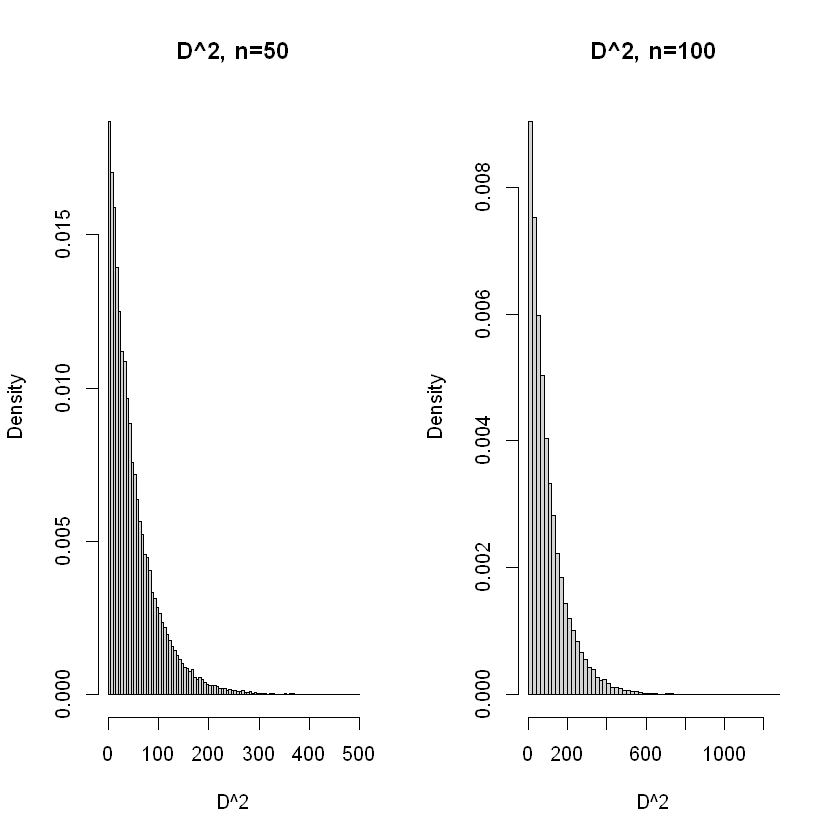

In [8]:
set.seed(631)
simulate_rw2d <- function(n, reps=5e4){
  theta <- matrix(runif(n*reps, 0, 2*pi), nrow=n)
  dx <- cos(theta); dy <- sin(theta)
  X <- colSums(dx); Y <- colSums(dy)
  D2 <- X^2 + Y^2
  D2
}
D2_50  <- simulate_rw2d(50, reps=5e4)
D2_100 <- simulate_rw2d(100, reps=5e4)

par(mfrow=c(1,2))
hist(D2_50,  breaks=80, probability=TRUE, main="D^2, n=50",  xlab="D^2")
hist(D2_100, breaks=80, probability=TRUE, main="D^2, n=100", xlab="D^2")
c(mean_50=mean(D2_50), mean_100=mean(D2_100))

mc_se_mean(D2_50); mc_se_mean(D2_100)

The sample means are within 1 SE of $50$ and $100$

---
## Problem 7 — MGFs & Distribution Identification (14 pts)

1. Derive MGF of Poisson(\(\lambda\)) and obtain mean/variance.  
2. Simulate 200k draws with \(\lambda=3\). Estimate mean/variance; overlay empirical vs theoretical pmf.

## 1)

Let $X\sim\text{Poisson}(\lambda)$ and $P(X=k)=e^{-\lambda}\lambda^k/k!$ for $k=0,1,2,\ldots$

MGF is $M_X(t)=E[e^{tX}]=\sum_{k=0}^\infty e^{tk}\,\frac{e^{-\lambda}\lambda^k}{k!}=e^{-\lambda}\sum_{k=0}^\infty\frac{(\lambda e^{t})^k}{k!}$

The is the Taylor series of $e^{\lambda e^t}$

$M_X(t)=e^{-\lambda}e^{\lambda e^t}=e^{\lambda(e^t-1)}$

$M_X'(t)=\lambda e^t\,e^{\lambda(e^t-1)}$

$M_X''(t)=\left(\lambda e^t+\lambda^2e^{2t}\right)e^{\lambda(e^t-1)}$

At $t=0$, $e^{\lambda(e^0-1)}=1$

$E[X]=M_X'(0)=\lambda$

$E[X^2]=M_X''(0)=\lambda+\lambda^2$

$Var(X)=E[X^2]-(E[X])^2=\lambda+\lambda^2-\lambda^2=\lambda$

## 2)

emp_mean  emp_var  th_mean   th_var 
3.002630 2.990018 3.000000 3.000000

[1] 0.003866535

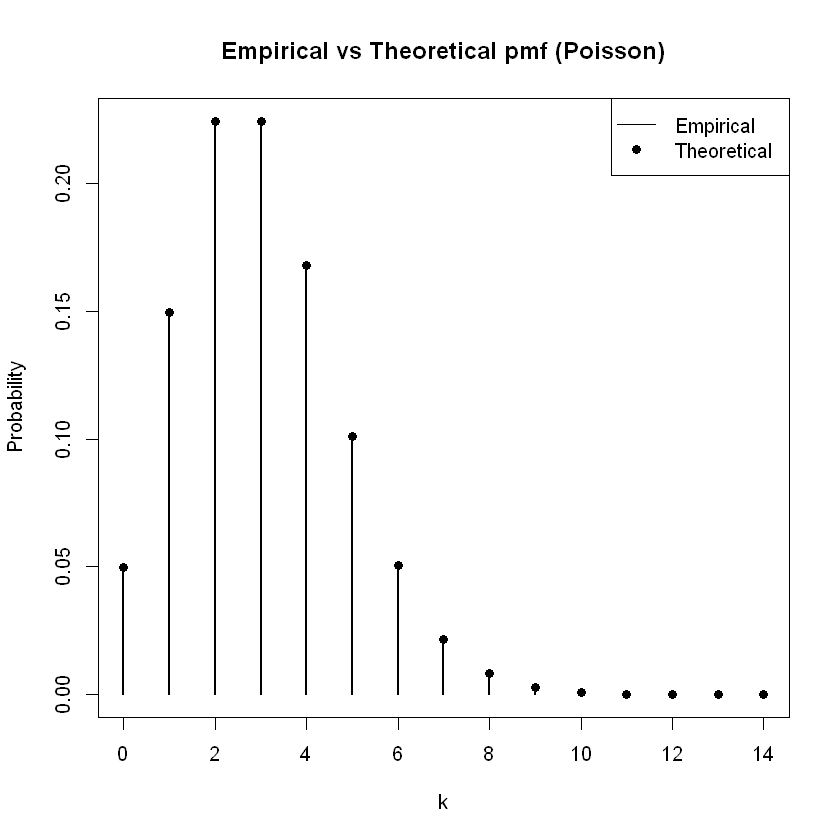

In [9]:
set.seed(631)
N <- 2e5; lambda <- 3
X <- rpois(N, lambda)
emp_mean <- mean(X); emp_var <- var(X)

tb <- table(factor(X, levels=0:max(X)))
probs_emp <- as.numeric(tb)/sum(tb)
k <- as.numeric(names(tb))
probs_th <- dpois(k, lambda=lambda)

plot(k, probs_emp, type='h', lwd=2, main='Empirical vs Theoretical pmf (Poisson)',
     xlab='k', ylab='Probability')
points(k, probs_th, pch=19)
legend('topright', legend=c('Empirical','Theoretical'), pch=c(NA,19), lty=c(1,NA))

c(emp_mean=emp_mean, emp_var=emp_var, th_mean=lambda, th_var=lambda)
mc_se_mean(X)

The sample mean and variance are both very close to $3.0$ with MC SE $\approx0.004$. The empirical pmf bars should sit almost exactly on the theoretical points. Mean and variance are equal because this is a Poisson distribution

---
## Problem 8 — Advanced Expectation Applications (16 pts)

Choose **two**:

(A) QuickSort: expected #comparisons \(\approx 2n\log n\) (large n). Simulate small n.  
(B) Runs in binary sequences: derive \(E[\#\text{runs}] = 1 + \frac{2nm}{n+m}\) for \(n\) ones and \(m\) zeros.  
(C) Coupon singletons: expected number of types observed exactly once when collecting full set.

Implement and validate your choices.

## C)

There are $N$ coupon types drawn uniformly with replacement

Let $S$ be the number of types that appear exactly once. Label types by the order collected where the $k$-th type $k = 1,\ldots,N$

Let $I_k=\{1\text{ if } k\text{-th collected type appears exactly once overall and 0 otherwise}\}$ and $S=\sum_{k=1}^N I_k$

At the stage where $i$ types have been collected ($i=k,\ldots,N-1$) there are 3 cases

- a new type is drawn with probability $\frac{N-i}{N}$
- type $k$ is drawn again with probability $\frac1N$
- another old type is drawn which doesn't matter

So the next relevant draw is new before it is type $k$ with probability $\frac{(N-i)/N}{(N-i)/N+1/N}=\frac{N-i}{N-i+1}$

Stages are independent so $P(I_k=1)=\prod_{i=k}^{N-1}\frac{N-i}{N-i+1}=\frac{N-k}{N-k+1}\cdot\frac{N-k-1}{N-k}\cdots\frac12=\frac{1}{N-k+1}$

For $k=N$ the product is empty and the last type collected is always new

$E[S]=\sum_{k=1}^N\frac{1}{N-k+1}=\sum_{j=1}^N\frac1j=H_N$

$H_{10}=\frac{7381}{2520}\approx 2.929$

In [10]:
# (C) Coupon singletons for N=10
singleton_after_full <- function(N){
  seen <- integer(N)
  while(any(seen==0)){
    ctype <- sample.int(N, 1)
    seen[ctype] <- seen[ctype] + 1L
  }
  sum(seen==1)
}
reps <- 2000
vals <- replicate(reps, singleton_after_full(10))
c(mean_singletons=mean(vals), se=sd(vals)/sqrt(reps))

mean_singletons              se 
     2.97600000      0.03804518

The simulated mean is within 1 MC SE of the theoretical values

## B)

There is a uniform random sequence of $n$ 1s and $m$ 0s with $L=n+m$ positions

Let $I_i= \{1\text{ if position } i \text{ and } i+1 \text{ differ and 0 otherwise}\} \text{ where } i=1,\ldots,L-1$ and $N = \#\text{ of runs}=1+\sum_{i=1}^{L-1}I_i$

The sequence always starts with a run. For a fixed $i$, the pair of values at $(i,i+1)$ is either (1,0) or (0,1) so 

$P(I_i=1)=\frac{n}{n+m}\cdot\frac{m}{n+m-1}+\frac{m}{n+m}\cdot\frac{n}{n+m-1}=\frac{2nm}{(n+m)(n+m-1)}$

By linearity of expectation

$E[N]=1+\sum_{i=1}^{n+m-1}P(I_i=1)=1+(n+m-1)\cdot\frac{2nm}{(n+m)(n+m-1)}=1+\frac{2nm}{n+m}$

In [11]:
# (B) Runs
runs_count <- function(vec) sum(c(1, diff(vec)!=0))
n <- 20; m <- 30; reps <- 5000
v_runs <- replicate(reps, runs_count(sample(c(rep(1,n), rep(0,m)))))
c(emp_mean=mean(v_runs), theory = 1 + 2*n*m/(n+m))
mc_se_mean(v_runs)

emp_mean   theory 
 25.0364  25.0000

[1] 0.04762046

When $n=20$, $m=30$, $E[N]=1+\frac{2(20)(30)}{50}=25$

The simulated mean is within 1 MC SE of the theoretical values

In [12]:
set.seed(631)
# (A) QuickSort comparisons (optional)
# qs_count <- function(a){
#   if(length(a) <= 1) return(0L)
#   pivot <- a[1]
#   rest <- a[-1]
#   comps <- length(rest)
#   left  <- rest[rest <= pivot]
#   right <- rest[rest >  pivot]
#   comps + qs_count(left) + qs_count(right)
# }
# avg_qs_comparisons <- function(n, reps=500){
#   mean(replicate(reps, qs_count(sample.int(n)) ))
# }
# n_vals <- 5:30
# avg_comp <- sapply(n_vals, avg_qs_comparisons, reps=300)
# data.frame(n=n_vals, avg_comp=avg_comp, approx_2nlogn=2*n_vals*log(n_vals))

